<a href="https://colab.research.google.com/github/moushe-21/CSE438-Lab/blob/main/CSE438Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


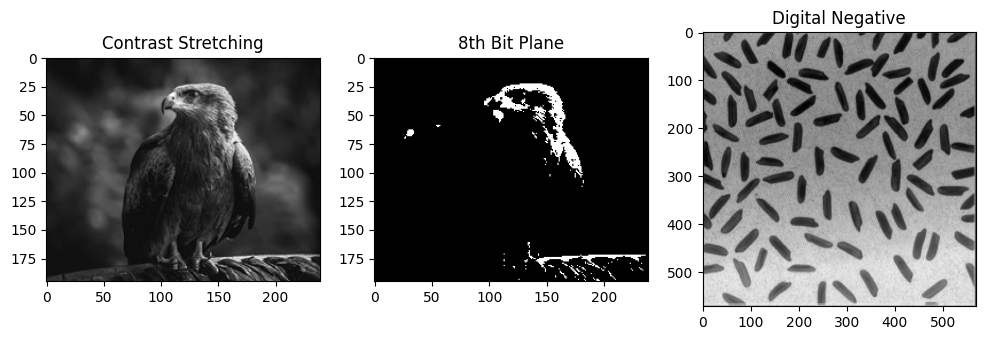

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
img_eagle = cv2.imread('/content/Picture1.jpg', 0)
img_brain = cv2.imread('/content/Picture2.png', 0)
contrast_stretched = None
bit_plane_8 = None
neg_img = None
if img_eagle is not None:
    min_val, max_val = np.min(img_eagle), np.max(img_eagle)
    if max_val - min_val != 0:
        contrast_stretched = ((img_eagle - min_val) / (max_val - min_val) * 255).astype(np.uint8)
    else:
        print("Warning: img_eagle has uniform pixel values, contrast stretching skipped.")
        contrast_stretched = img_eagle # Use original if no contrast change needed

    bit_plane_8 = (img_eagle & 128) # 8th bit is 2^7 = 128
else:
    print("Error: Could not load /content/Picture1.jpg for contrast stretching and bit plane slicing.")

if img_brain is not None:
    # Formula: s = (L - 1) - r
    neg_img = 255 - img_brain
else:
    print("Error: Could not load /content/Picture2.png for digital negative.")

# Visualization
plt.figure(figsize=(12, 4))
if contrast_stretched is not None:
    plt.subplot(1,3,1), plt.imshow(contrast_stretched, cmap='gray'), plt.title('Contrast Stretching')
else:
    plt.subplot(1,3,1), plt.title('Contrast Stretching (Image not loaded)')

if bit_plane_8 is not None:
    plt.subplot(1,3,2), plt.imshow(bit_plane_8, cmap='gray'), plt.title('8th Bit Plane')
else:
    plt.subplot(1,3,2), plt.title('8th Bit Plane (Image not loaded)')

if neg_img is not None:
    plt.subplot(1,3,3), plt.imshow(neg_img, cmap='gray'), plt.title('Digital Negative')
else:
    plt.subplot(1,3,3), plt.title('Digital Negative (Image not loaded)')

plt.show()

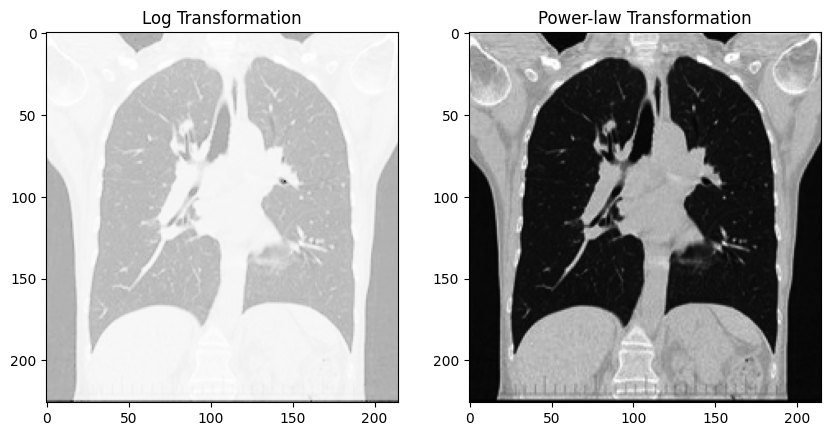

In [ ]:
img_rice = cv2.imread('/content/Picture5.jpg', 0) # Changed path to an existing file


log_transformed = None
power_law = None

if img_rice is not None:

    img_rice_float = img_rice.astype(np.float64)


    max_val_float = np.max(img_rice_float)
    if max_val_float == 0:
        c = 0
    else:
        c = 255 / np.log(1 + max_val_float)

    # Apply log transformation
    log_transformed_float = c * np.log(img_rice_float + 1)


    log_transformed = np.clip(log_transformed_float, 0, 255).astype(np.uint8)


    gamma = 2.0 # Gamma > 1 image dark korbe, Gamma < 1 bright korbe

    power_law = np.array(255 * (img_rice_float / 255) ** gamma, dtype='uint8')
else:
    print("Error: Could not load /content/Picture5.jpg for transformations.")

# Plotting
plt.figure(figsize=(10, 5))

if log_transformed is not None:
    plt.subplot(1,2,1), plt.imshow(log_transformed, cmap='gray'), plt.title('Log Transformation')
else:
    plt.subplot(1,2,1), plt.title('Log Transformation (Image not loaded)')

if power_law is not None:
    plt.subplot(1,2,2), plt.imshow(power_law, cmap='gray'), plt.title('Power-law Transformation')
else:
    plt.subplot(1,2,2), plt.title('Power-law Transformation (Image not loaded)')

plt.show()

/tmp/ipython-input-2336606079.py:8: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.subplot(1,2,1), plt.hist(img_xray.ravel(), 256, [0,256]), plt.title('Original Histogram')
/tmp/ipython-input-2336606079.py:9: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.subplot(1,2,2), plt.hist(equ.ravel(), 256, [0,256]), plt.title('Equalized Histogram')


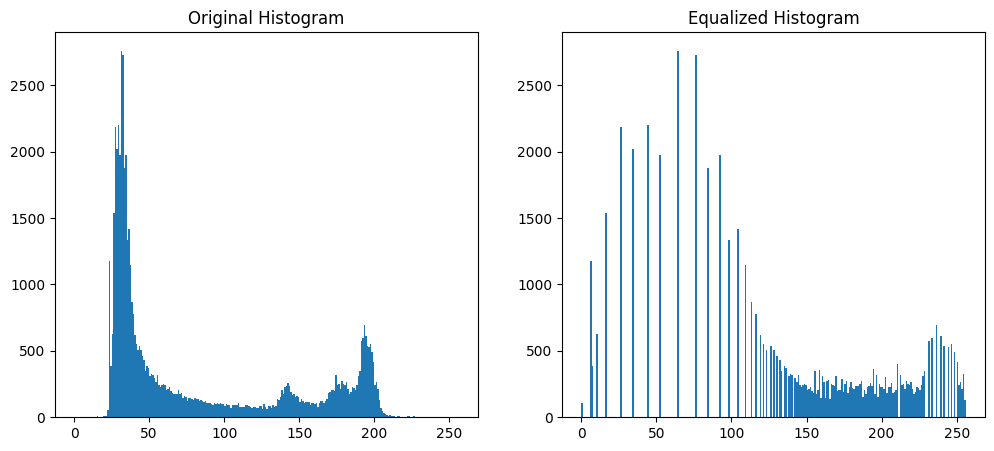

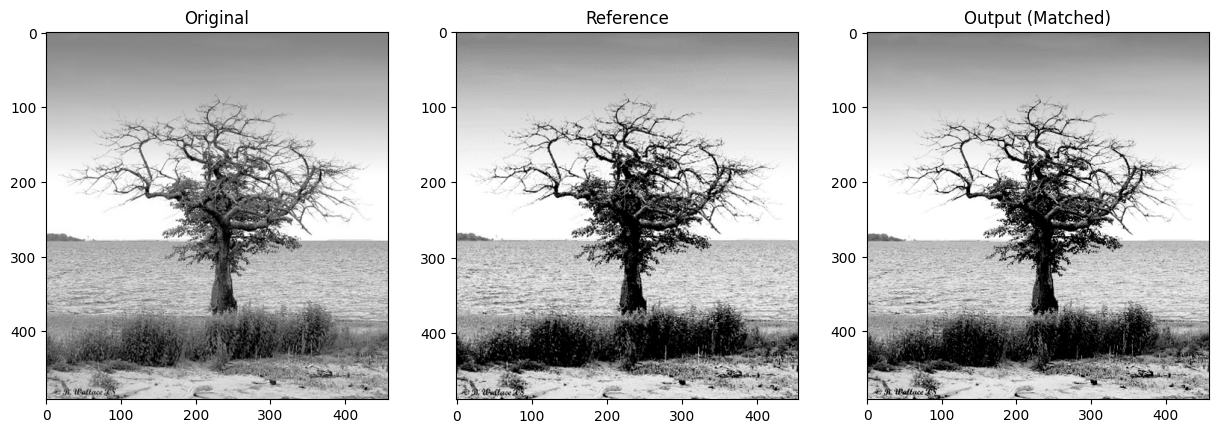

In [ ]:
# --- Histogram Equalization [cite: 7] ---
img_xray = cv2.imread('/content/Picture6.jpg', 0) # Changed path to an existing file
equ = None

plt.figure(figsize=(12, 5))
if img_xray is not None:
    equ = cv2.equalizeHist(img_xray)
    plt.subplot(1,2,1), plt.hist(img_xray.ravel(), 256, [0,256]), plt.title('Original Histogram')
    plt.subplot(1,2,2), plt.hist(equ.ravel(), 256, [0,256]), plt.title('Equalized Histogram')
else:
    print("Error: Could not load /content/Picture6.jpg for Histogram Equalization.")
    plt.subplot(1,2,1), plt.title('Original Histogram (Image not loaded)')
    plt.subplot(1,2,2), plt.title('Equalized Histogram (Image not loaded)')
plt.show()

# --- Histogram Matching [cite: 5, 6] ---
from skimage import exposure

img_tree = cv2.imread('/content/Picture3.jpg', 0) # Changed path to an existing file
ref_tree = cv2.imread('/content/Picture4.png', 0) # Changed path to an existing file

matched = None

if img_tree is not None and ref_tree is not None:
    matched = exposure.match_histograms(img_tree, ref_tree)

    # Show Original, Reference and Matched images [cite: 6]
    titles = ['Original', 'Reference', 'Output (Matched)']
    images = [img_tree, ref_tree, matched]

    plt.figure(figsize=(15, 5))
    for i in range(3):
        plt.subplot(1, 3, i+1)
        plt.imshow(images[i], cmap='gray')
        plt.title(titles[i])
    plt.show()
else:
    print("Error: Could not load images for Histogram Matching. Ensure /content/Picture3.jpg and /content/Picture4.png exist.")
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1), plt.title('Original (Image not loaded)')
    plt.subplot(1, 3, 2), plt.title('Reference (Image not loaded)')
    plt.subplot(1, 3, 3), plt.title('Output (Image not loaded)')
    plt.show()

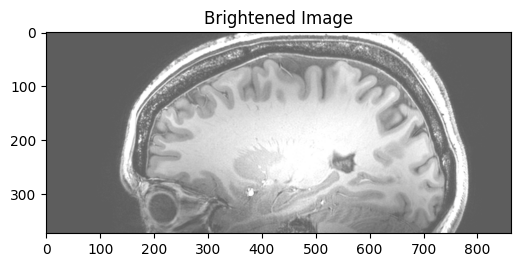

In [ ]:
img_forest = cv2.imread('/content/Picture7.png') # Changed path to an existing file

if img_forest is not None:

    bright_img = cv2.convertScaleAbs(img_forest, alpha=1.0, beta=50) # beta is brightness offset

    plt.figure(figsize=(6, 6))
    if bright_img.ndim == 3:
        plt.imshow(cv2.cvtColor(bright_img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(bright_img, cmap='gray')
    plt.title('Brightened Image')
    plt.show()
else:
    print("Error: Could not load /content/Picture7.png. Please ensure the file exists and is accessible.")